# Аналіз відгуків користувачів про мобільні застосунки

**Курсова робота** — «Мови програмування для аналізу даних»  
Тема: аналіз відгуків користувачів Google Play Store

## Мета

Дослідити зв'язок між метаданими мобільних застосунків (категорія, рейтинг, ціна, кількість встановлень) та відгуками користувачів (настрій, полярність, суб'єктивність); виявити закономірності, побудувати візуалізації та підготувати експорт для інтерактивної панелі Tableau Public.

## Джерело даних

- **Kaggle:** [lava18/google-play-store-apps](https://www.kaggle.com/datasets/lava18/google-play-store-apps)
- `googleplaystore.csv` — метадані застосунків
- `googleplaystore_user_reviews.csv` — відгуки з мітки sentiment (VADER-подібна полярність)

## Дослідницькі питання (РП)

1. Як розподіляється настрій відгуків і які категорії мають найнижчу середню полярність?
2. Чи пов'язані `Rating` та `Sentiment_Polarity` / `Sentiment_Subjectivity`?
3. Чим відрізняються настрій і полярність для безплатних (Free) і платних (Paid) застосунків?
4. Які категорії — лідери та аутсайдери за кількістю відгуків і середньою оцінкою?
5. Як змінюються часові показники оновлень (`Last Updated`) за категоріями?

## Стек

Python · Pandas · NumPy · Matplotlib · Seaborn · Tableau Public


## 1. Завантаження та первинне дослідження даних


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

RANDOM_STATE = 42
BASE = Path("..")  # notebooks/ -> kursova/
RAW = BASE / "data" / "raw"
PROCESSED = BASE / "data" / "processed"
FIGURES = BASE / "results" / "figures"
EXPORTS = BASE / "results" / "exports"
for p in (PROCESSED, FIGURES, EXPORTS):
    p.mkdir(parents=True, exist_ok=True)

print("Pandas:", pd.__version__)


Pandas: 3.1.0


In [2]:
apps = pd.read_csv(RAW / "googleplaystore.csv")
reviews = pd.read_csv(RAW / "googleplaystore_user_reviews.csv")

print(f"apps:    {apps.shape[0]:,} рядків × {apps.shape[1]} ознак")
print(f"reviews: {reviews.shape[0]:,} рядків × {reviews.shape[1]} ознак")


apps:    10,841 рядків × 13 ознак
reviews: 64,295 рядків × 5 ознак


In [3]:
print("=== Структура apps ===")
display(apps.head(3))
print(apps.dtypes)
print("\nshape:", apps.shape)
print("\n=== Описова статистика (числові поля кастомні) ===")
display(apps.describe(include="all").T)


=== Структура apps ===


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up


App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object

shape: (10841, 13)

=== Описова статистика (числові поля кастомні) ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9367.0,NaN,NaN,NaN,4.193338,0.537431,1.0,4.0,4.3,4.5,19.0
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("=== Структура reviews ===")
display(reviews.head(3))
print(reviews.dtypes)
print("\nshape:", reviews.shape)
print("\nSentiment value_counts:")
print(reviews["Sentiment"].value_counts(dropna=False))
print("\ndescribe:")
display(reviews[["Sentiment_Polarity", "Sentiment_Subjectivity"]].describe())


=== Структура reviews ===


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN


App                           str
Translated_Review             str
Sentiment                     str
Sentiment_Polarity        float64
Sentiment_Subjectivity    float64
dtype: object

shape: (64295, 5)

Sentiment value_counts:
Sentiment
NaN         26863
Positive    23998
Negative     8271
Neutral      5163
Name: count, dtype: int64

describe:


,Sentiment_Polarity,Sentiment_Subjectivity
count,37432.000000,37432.000000
mean,0.182146,0.492704
std,0.351301,0.259949
min,-1.000000,0.000000
25%,0.000000,0.357143
50%,0.150000,0.514286
75%,0.400000,0.650000
max,1.000000,1.000000


In [5]:
print("Кількість унікальних App у apps:   ", apps["App"].nunique())
print("Кількість унікальних App у reviews:", reviews["App"].nunique())
overlap = set(apps["App"]) & set(rev_app for rev_app in reviews["App"].unique())
print("Перетин ключа App:                 ", len(overlap))
print("\nКатегорії (топ-10):")
print(apps["Category"].value_counts().head(10))
print("\nType:")
print(apps["Type"].value_counts(dropna=False))


Кількість унікальних App у apps:    9660
Кількість унікальних App у reviews: 1074
Перетин ключа App:                  1020

Категорії (топ-10):
Category
FAMILY             1972
GAME               1144
TOOLS               843
MEDICAL             463
BUSINESS            460
PRODUCTIVITY        424
PERSONALIZATION     392
COMMUNICATION       387
SPORTS              384
LIFESTYLE           382
Name: count, dtype: int64

Type:
Type
Free    10039
Paid      800
NaN         1
0           1
Name: count, dtype: int64


### Висновок етапу 1

- Два пов'язані набори даних із ключем `App`.
- `apps` містить категоріальні (`Category`, `Type`, `Genres`), числові-у-рядках (`Reviews`, `Installs`, `Price`), часову (`Last Updated`) ознаки.
- `reviews` містить текст відгуку, мітку `Sentiment`, `Sentiment_Polarity` ∈ [−1, 1], `Sentiment_Subjectivity` ∈ [0, 1].
- Багато порожніх відгуків (~42%) і дублікатів — потрібне очищення.
- Відомий «брудний» рядок `Category=1.9`, `Rating=19` (зсув стовпців).


## 2. Попереднє опрацювання даних


In [6]:
# --- apps: дублікати за назвою (залишаємо перший запис) ---
n_apps0 = len(apps)
apps = apps.drop_duplicates(subset=["App"], keep="first").copy()
print(f"apps: видалено дублікатів за App: {n_apps0 - len(apps)}")

# --- apps: відомий зсув рядка 1.9 ---
bad_cat = apps[~apps["Category"].astype(str).str.match(r"^[A-Z][A-Z_]*$")]
print("Некоректні Category:", bad_cat["Category"].unique().tolist())
apps = apps[apps["Category"].astype(str).str.match(r"^[A-Z][A-Z_]*$")].copy()
print(f"apps: після фільтру Category — {len(apps)} рядків")

# Rating поза [1, 5]
bad_rating = apps[(apps["Rating"].notna()) & ((apps["Rating"] < 1) | (apps["Rating"] > 5))]
print(f"Rating поза [1,5]: {len(bad_rating)}")
apps.loc[apps["Rating"] > 5, "Rating"] = np.nan


apps: видалено дублікатів за App: 1181
Некоректні Category: ['1.9']
apps: після фільтру Category — 9659 рядків
Rating поза [1,5]: 0


In [7]:
# --- apps: числові перетворення ---
def to_int_reviews(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace(",", "")
    if s.endswith("M"):
        return float(s[:-1]) * 1_000_000
    if s.endswith("K"):
        return float(s[:-1]) * 1_000
    try:
        return float(s)
    except ValueError:
        return np.nan


def to_num_installs(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace(",", "").replace("+", "")
    try:
        return float(s)
    except ValueError:
        return np.nan


def to_num_price(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace("$", "").replace(",", "")
    try:
        return float(s)
    except ValueError:
        return np.nan


def to_num_size_mb(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s.lower().startswith("varies"):
        return np.nan
    try:
        if s.endswith("M"):
            return float(s[:-1])
        if s.endswith("k"):
            return float(s[:-1]) / 1024.0
        return float(s)
    except ValueError:
        return np.nan


apps["Reviews"] = apps["Reviews"].map(to_int_reviews)
apps["Installs_num"] = apps["Installs"].map(to_num_installs)
apps["Price_usd"] = apps["Price"].map(to_num_price)
apps["Size_mb"] = apps["Size"].map(to_num_size_mb)
apps["Last_Updated"] = pd.to_datetime(apps["Last Updated"], errors="coerce")
apps["Type"] = apps["Type"].replace({"0": np.nan})
apps["Type"] = apps["Type"].fillna("Free")

print(apps[["Rating", "Reviews", "Installs_num", "Price_usd", "Size_mb"]].describe().T)
print("\nLast_Updated NaT:", apps["Last_Updated"].isna().sum())
print("Type:", apps["Type"].value_counts().to_dict())


               count          mean           std       min     25%       50%  \
Rating        8196.0  4.173243e+00  5.366247e-01  1.000000     4.0       4.3   
Reviews       9659.0  2.165926e+05  1.831320e+06  0.000000    25.0     967.0   
Installs_num  9659.0  7.777507e+06  5.375828e+07  0.000000  1000.0  100000.0   
Price_usd     9659.0  1.099299e+00  1.685215e+01  0.000000     0.0       0.0   
Size_mb       8432.0  2.039490e+01  2.182790e+01  0.008301     4.6      12.0   

                    75%           max  
Rating              4.5  5.000000e+00  
Reviews         29401.0  7.815831e+07  
Installs_num  1000000.0  1.000000e+09  
Price_usd           0.0  4.000000e+02  
Size_mb            28.0  1.000000e+02  

Last_Updated NaT: 0
Type: {'Free': 8903, 'Paid': 756}


In [8]:
# --- reviews: очищення ---
print("reviews до:", len(reviews))
print("порожній Translated_Review:", reviews["Translated_Review"].isna().sum())
print("порожній Sentiment:", reviews["Sentiment"].isna().sum())
print("повні дублікати:", reviews.duplicated().sum())

reviews = reviews.dropna(subset=["Translated_Review", "Sentiment"]).copy()
reviews = reviews.drop_duplicates(subset=["App", "Translated_Review"], keep="first").copy()
reviews["Sentiment_Polarity"] = pd.to_numeric(reviews["Sentiment_Polarity"], errors="coerce")
reviews["Sentiment_Subjectivity"] = pd.to_numeric(reviews["Sentiment_Subjectivity"], errors="coerce")
reviews = reviews.dropna(subset=["Sentiment_Polarity", "Sentiment_Subjectivity"]).copy()

print("reviews після:", len(reviews))
print("Sentiment:", reviews["Sentiment"].value_counts().to_dict())
print("полярність межі: [", reviews["Sentiment_Polarity"].min(), ",", reviews["Sentiment_Polarity"].max(), "]")
print("суб'єктивність межі: [", reviews["Sentiment_Subjectivity"].min(), ",", reviews["Sentiment_Subjectivity"].max(), "]")


reviews до: 64295
порожній Translated_Review: 26868
порожній Sentiment: 26863
повні дублікати: 33616
reviews після: 29692
Sentiment: {'Positive': 19015, 'Negative': 6321, 'Neutral': 4356}
полярність межі: [ -1.0 , 1.0 ]
суб'єктивність межі: [ 0.0 , 1.0 ]


In [9]:
# Кількісний звіт очищення
report = pd.DataFrame(
    {
        "метрика": [
            "apps: рядків спочатку",
            "apps: після дедуплікації та фільтру Category",
            "apps: % пропусків Rating",
            "reviews: рядків спочатку",
            "reviews: видалено (NaN текст/sentiment/дублікати)",
            "reviews: % пропусків Rating у apps (після)",
        ],
        "значення": [
            n_apps0,
            len(apps),
            round(100 * apps["Rating"].isna().mean(), 2),
            64295,
            64295 - len(reviews),
            round(100 * apps["Rating"].isna().mean(), 2),
        ],
    }
)
display(report)
print(
    f"Частка видалених reviews: "
    f"{100 * (64295 - len(reviews)) / 64295:.1f}%"
)


,метрика,значення
0,apps: рядків спочатку,10841.00
1,apps: після дедуплікації та фільтру Category,9659.00
2,apps: % пропусків Rating,15.15
3,reviews: рядків спочатку,64295.00
4,reviews: видалено (NaN текст/sentiment/дублікати),34603.00
5,reviews: % пропусків Rating у apps (після),15.15


Частка видалених reviews: 53.8%


### Висновок етапу 2

- З `apps` прибрано дублікати за назвою, некоректний рядок із `Category=1.9` / `Rating=19`.
- `Reviews`, `Installs`, `Price`, `Size` перетворено на числа; `Last Updated` → datetime.
- `Type` заповнено `Free` для одного NaN.
- З `reviews` прибрано порожні тексти/мітки та повні дублікати (велика частка).
- Викидів у полярності/суб'єктивності поза очікуваними межами не виявлено.


## 3. Об'єднання даних і створення аналітичних ознак


In [10]:
# Об'єднання 1: відгуки × метадані застосунків
df = reviews.merge(
    apps[
        [
            "App",
            "Category",
            "Rating",
            "Reviews",
            "Type",
            "Price_usd",
            "Size_mb",
            "Installs_num",
            "Genres",
            "Content Rating",
            "Last_Updated",
        ]
    ],
    on="App",
    how="inner",
)
print(f"Об'єднано: {len(df):,} рядків × {df.shape[1]} ознак")
print("Унікальних App:", df["App"].nunique())
print("Категорій:", df["Category"].nunique())
df.head(3)


Об'єднано: 28,250 рядків × 15 ознак


Унікальних App: 816
Категорій: 33


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity,Category,Rating,Reviews,Type,Price_usd,Size_mb,Installs_num,Genres,Content Rating,Last_Updated
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333,HEALTH_AND_FITNESS,4.0,2490.0,Free,0.0,3.8,500000.0,Health & Fitness,Everyone 10+,2017-02-17
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462,HEALTH_AND_FITNESS,4.0,2490.0,Free,0.0,3.8,500000.0,Health & Fitness,Everyone 10+,2017-02-17
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000,HEALTH_AND_FITNESS,4.0,2490.0,Free,0.0,3.8,500000.0,Health & Fitness,Everyone 10+,2017-02-17


In [11]:
# --- Нові аналітичні ознаки ---

# 1) Довжина відгуку (кількість символів)
df["Review_Length"] = df["Translated_Review"].astype(str).str.len()

# 2) Бінарна мітка «дружній відгук»: polarity > 0
df["Is_Positive"] = (df["Sentiment_Polarity"] > 0).astype(int)

# 3) Ступінь інсталяцій (категоріальні інтервали)
bins = [-np.inf, 1e3, 1e4, 1e5, 1e6, 1e7, np.inf]
labels = ["<1K", "1K–10K", "10K–100K", "100K–1M", "1M–10M", ">10M"]
df["Install_Bracket"] = pd.cut(df["Installs_num"], bins=bins, labels=labels)

# 4) Рік останнього оновлення застосунку
df["Year_Last_Update"] = df["Last_Updated"].dt.year

# 5) Агрегована таблиця за застосунком (для другого об'єднання / ranking)
app_stats = (
    df.groupby("App", as_index=False)
    .agg(
        n_reviews=("Sentiment_Polarity", "size"),
        mean_polarity=("Sentiment_Polarity", "mean"),
        mean_subjectivity=("Sentiment_Subjectivity", "mean"),
        mean_rating_app=("Rating", "mean"),
        category=("Category", "first"),
        app_type=("Type", "first"),
    )
    .sort_values("n_reviews", ascending=False)
)
display(app_stats.head(10))

# Об'єднання 2: прикріплюємо агрегати назад до рядків відгуків
df = df.merge(
    app_stats[["App", "n_reviews", "mean_polarity"]],
    on="App",
    how="left",
    suffixes=("", "_app"),
)
print("Після merge з app_stats:", df.shape)
df[["Review_Length", "Is_Positive", "Install_Bracket", "Year_Last_Update", "n_reviews"]].head()


,App,n_reviews,mean_polarity,mean_subjectivity,mean_rating_app,category,app_type
526,Facebook,130,-0.005909,0.460871,4.1,SOCIAL,Free
491,Episode - Choose Your Story,124,0.082734,0.479934,4.3,GAME,Free
109,Angry Birds Classic,107,-0.023874,0.531806,4.4,GAME,Free
537,Family Locator - GPS Tracker,105,0.341109,0.532066,4.4,LIFESTYLE,Free
706,Google Photos,101,0.187021,0.509305,4.5,PHOTOGRAPHY,Free
21,8fit Workouts & Meal Planner,100,0.297167,0.553566,4.6,HEALTH_AND_FITNESS,Free
301,Calorie Counter - Macros,100,0.247519,0.512675,4.0,HEALTH_AND_FITNESS,Free
302,Calorie Counter - MyFitnessPal,99,0.232979,0.451221,4.6,HEALTH_AND_FITNESS,Free
350,ColorNote Notepad Notes,99,0.286861,0.516958,4.6,PRODUCTIVITY,Free
61,Adobe Acrobat Reader,98,0.145425,0.486125,4.3,PRODUCTIVITY,Free


Після merge з app_stats: (28250, 21)


,Review_Length,Is_Positive,Install_Bracket,Year_Last_Update,n_reviews
0,122,1,100K–1M,2017,95
1,47,1,100K–1M,2017,95
2,42,1,100K–1M,2017,95
3,12,1,100K–1M,2017,95
4,8,1,100K–1M,2017,95


### Нові ознаки

| Ознака | Призначення |
|--------|-------------|
| `Review_Length` | Довжина тексту відгуку — може корелювати зі суб'єктивністю |
| `Is_Positive` | Бінарна мітка для частки позитивних відгуків |
| `Install_Bracket` | Інтервали встановлень — для групового порівняння |
| `Year_Last_Update` | Часовий показник оновлення застосунку |
| `n_reviews` (з app_stats) | Кількість відгуків за застосунком (для ranking) |


## 4. Статистичний та аналітичний аналіз


### 4.1 Описова статистика


In [12]:
num_cols = [
    "Rating",
    "Sentiment_Polarity",
    "Sentiment_Subjectivity",
    "Review_Length",
    "Reviews",
    "Installs_num",
    "Price_usd",
]
desc = df[num_cols].describe().T
desc["median"] = df[num_cols].median()
desc["skew"] = df[num_cols].skew()
display(desc[["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max", "skew"]])


,count,mean,median,std,min,25%,50%,75%,max,skew
Rating,28250.0,4.290577e+00,4.300000e+00,3.094012e-01,2.6,4.10,4.300000e+00,4.500000e+00,4.900000e+00,-1.292396
Sentiment_Polarity,28250.0,1.882729e-01,1.571429e-01,3.546569e-01,-1.0,0.00,1.571429e-01,4.191174e-01,1.000000e+00,-0.125503
Sentiment_Subjectivity,28250.0,4.923033e-01,5.158288e-01,2.640105e-01,0.0,0.35,5.158288e-01,6.500000e-01,1.000000e+00,-0.302880
Review_Length,28250.0,1.079614e+02,8.100000e+01,1.030988e+02,2.0,31.00,8.100000e+01,1.550000e+02,2.713000e+03,2.524592
Reviews,28250.0,1.184521e+06,5.151700e+04,5.927353e+06,114.0,8722.00,5.151700e+04,3.100660e+05,7.815831e+07,10.866468
Installs_num,28250.0,3.276183e+07,5.000000e+06,1.249328e+08,1000.0,1000000.00,5.000000e+06,1.000000e+07,1.000000e+09,6.823117
Price_usd,28250.0,1.037335e-01,0.000000e+00,1.344401e+00,0.0,0.00,0.000000e+00,0.000000e+00,2.999000e+01,17.737865


### 4.2 Розподіл настроїв (РП.1)


In [13]:
sentiment_share = (
    df["Sentiment"]
    .value_counts(normalize=True)
    .rename_axis("Sentiment")
    .reset_index(name="share")
)
sentiment_share["share_pct"] = (sentiment_share["share"] * 100).round(1)
display(sentiment_share)

print("Середня полярність за настроєм:")
display(
    df.groupby("Sentiment")["Sentiment_Polarity"]
    .agg(["count", "mean", "median", "std"])
    .round(3)
)


,Sentiment,share,share_pct
0,Positive,0.642124,64.2
1,Negative,0.214407,21.4
2,Neutral,0.143469,14.3


Середня полярність за настроєм:


,count,mean,median,std
Sentiment,,,,
Negative,6057,-0.262,-0.190,0.239
Neutral,4053,0.000,0.000,0.000
Positive,18140,0.381,0.344,0.254


In [14]:
# Середня полярність за категоріями (мін. 50 відгуків)
cat_pol = (
    df.groupby("Category")
    .agg(
        n=("Sentiment_Polarity", "size"),
        mean_polarity=("Sentiment_Polarity", "mean"),
        mean_subjectivity=("Sentiment_Subjectivity", "mean"),
        mean_rating=("Rating", "mean"),
        positive_share=("Is_Positive", "mean"),
    )
    .query("n >= 50")
    .sort_values("mean_polarity")
)
print("ТОП-10 категорій з НАЙНИЖЧОЮ середньою полярністю:")
display(cat_pol.head(10).round(3))
print("\nТОП-10 категорій з НАЙВИЩОЮ середньою полярністю:")
display(cat_pol.tail(10).round(3))


ТОП-10 категорій з НАЙНИЖЧОЮ середньою полярністю:


,n,mean_polarity,mean_subjectivity,mean_rating,positive_share
Category,,,,,
GAME,4344,0.069,0.504,4.432,0.591
SOCIAL,661,0.108,0.478,4.135,0.555
FAMILY,1802,0.119,0.506,4.354,0.620
ENTERTAINMENT,827,0.134,0.484,4.103,0.596
VIDEO_PLAYERS,326,0.136,0.478,4.242,0.567
NEWS_AND_MAGAZINES,733,0.153,0.474,4.243,0.607
COMMUNICATION,855,0.172,0.477,4.241,0.608
FINANCE,1336,0.172,0.481,4.253,0.629
DATING,1087,0.179,0.506,4.080,0.615



ТОП-10 категорій з НАЙВИЩОЮ середньою полярністю:


,n,mean_polarity,mean_subjectivity,mean_rating,positive_share
Category,,,,,
BOOKS_AND_REFERENCE,617,0.259,0.475,4.370,0.692
MAPS_AND_NAVIGATION,189,0.260,0.459,4.319,0.667
PERSONALIZATION,961,0.275,0.525,4.339,0.695
FOOD_AND_DRINK,583,0.280,0.525,4.369,0.741
WEATHER,194,0.281,0.486,4.259,0.696
HEALTH_AND_FITNESS,1621,0.294,0.513,4.405,0.779
EDUCATION,644,0.297,0.499,4.220,0.758
PARENTING,256,0.313,0.501,4.252,0.707
AUTO_AND_VEHICLES,283,0.343,0.525,4.580,0.813


### 4.3 Групування: Free vs Paid (РП.3)


In [15]:
type_stats = (
    df.groupby("Type")
    .agg(
        n=("Sentiment_Polarity", "size"),
        mean_polarity=("Sentiment_Polarity", "mean"),
        median_polarity=("Sentiment_Polarity", "median"),
        mean_subjectivity=("Sentiment_Subjectivity", "mean"),
        mean_rating=("Rating", "mean"),
        positive_share=("Is_Positive", "mean"),
        median_price=("Price_usd", "median"),
    )
    .round(3)
)
display(type_stats)


,n,mean_polarity,median_polarity,mean_subjectivity,mean_rating,positive_share,median_price
Type,,,,,,,
Free,27947,0.188,0.156,0.492,4.290,0.641,0.00
Paid,303,0.218,0.217,0.500,4.308,0.756,9.99


### 4.4 Кореляції взаємозв'язків (РП.2)


In [16]:
corr_cols = [
    "Rating",
    "Sentiment_Polarity",
    "Sentiment_Subjectivity",
    "Review_Length",
    "Reviews",
    "Installs_num",
    "Price_usd",
]
corr = df[corr_cols].corr(method="pearson")
display(corr.round(3))

print("\nНайсильніші |кореляції| (між різними ознаками):")
pairs = (
    corr.where(~np.eye(len(corr), dtype=bool))
    .stack()
    .reset_index()
)
pairs.columns = ["a", "b", "r"]
pairs["abs_r"] = pairs["r"].abs()
pairs = pairs.sort_values("abs_r", ascending=False).drop_duplicates(subset=["abs_r"])
display(pairs.head(10).round(3))


,Rating,Sentiment_Polarity,Sentiment_Subjectivity,Review_Length,Reviews,Installs_num,Price_usd
Rating,1.000,0.112,0.075,0.019,0.042,0.026,-0.013
Sentiment_Polarity,0.112,1.000,0.272,-0.153,-0.069,-0.053,0.021
Sentiment_Subjectivity,0.075,0.272,1.000,0.029,-0.005,-0.005,-0.000
Review_Length,0.019,-0.153,0.029,1.000,0.138,0.133,0.022
Reviews,0.042,-0.069,-0.005,0.138,1.000,0.628,-0.015
Installs_num,0.026,-0.053,-0.005,0.133,0.628,1.000,-0.020
Price_usd,-0.013,0.021,-0.000,0.022,-0.015,-0.020,1.000



Найсильніші |кореляції| (між різними ознаками):


,a,b,r,abs_r
33,Reviews,Installs_num,0.628,0.628
9,Sentiment_Polarity,Sentiment_Subjectivity,0.272,0.272
22,Review_Length,Sentiment_Polarity,-0.153,0.153
31,Reviews,Review_Length,0.138,0.138
26,Review_Length,Installs_num,0.133,0.133
1,Rating,Sentiment_Polarity,0.112,0.112
14,Sentiment_Subjectivity,Rating,0.075,0.075
11,Sentiment_Polarity,Reviews,-0.069,0.069
12,Sentiment_Polarity,Installs_num,-0.053,0.053
28,Reviews,Rating,0.042,0.042


> **Примітка:** кореляція не означає причинно-наслідковий зв'язок. Зв'язок `Rating` ↔ `Sentiment_Polarity` очікуваний (оцінка застосунку та тональність текстів пов'язані з досвідом використання), але не є доказом каузальності.


### 4.5 Ранжування лідерів і аутсайдерів (РП.4)


In [17]:
# Категорії за кількістю відгуків
cat_volume = (
    df.groupby("Category")
    .agg(n_reviews=("Sentiment_Polarity", "size"), mean_rating=("Rating", "mean"))
    .sort_values("n_reviews", ascending=False)
)
display(cat_volume.head(10).round(2))

# Категорії за середньою оцінкою (мін. 30 унікальних app)
cat_rating = (
    apps.groupby("Category")
    .agg(n_apps=("App", "nunique"), mean_rating=("Rating", "mean"), median_rating=("Rating", "median"))
    .query("n_apps >= 30")
    .sort_values("mean_rating")
)
print("Аутсайдери за середньою оцінкою (apps):")
display(cat_rating.head(8).round(3))
print("Лідери за середньою оцінкою (apps):")
display(cat_rating.tail(8).round(3))


,n_reviews,mean_rating
Category,,
GAME,4344,4.43
FAMILY,1802,4.35
HEALTH_AND_FITNESS,1621,4.41
TOOLS,1398,4.25
FINANCE,1336,4.25
TRAVEL_AND_LOCAL,1331,4.29
SPORTS,1216,4.28
MEDICAL,1156,4.13
PRODUCTIVITY,1135,4.35


Аутсайдери за середньою оцінкою (apps):


,n_apps,mean_rating,median_rating
Category,,,
DATING,171,3.970,4.1
MAPS_AND_NAVIGATION,131,4.036,4.2
TOOLS,827,4.040,4.2
VIDEO_PLAYERS,163,4.045,4.2
TRAVEL_AND_LOCAL,219,4.070,4.2
LIFESTYLE,369,4.093,4.2
BUSINESS,420,4.098,4.2
FINANCE,345,4.116,4.3


Лідери за середньою оцінкою (apps):


,n_apps,mean_rating,median_rating
Category,,,
GAME,959,4.247,4.3
BEAUTY,53,4.279,4.3
PARENTING,60,4.300,4.4
PERSONALIZATION,376,4.332,4.4
BOOKS_AND_REFERENCE,222,4.345,4.5
ART_AND_DESIGN,64,4.357,4.4
EDUCATION,119,4.364,4.4
EVENTS,64,4.436,4.5


In [18]:
# Зведена таблиця: категорія × sentiment (кількість)
pivot_sent = pd.crosstab(df["Category"], df["Sentiment"])
# Частки в межах категорії
pivot_share = pivot_sent.div(pivot_sent.sum(axis=1), axis=0).round(3)

# Обмежимо топ-15 категорій за обсягом для читабельності
top_cats = cat_volume.head(15).index.tolist()
display(pivot_sent.loc[top_cats])
display(pivot_share.loc[top_cats])
pivot_share.loc[top_cats].to_csv(EXPORTS / "pivot_category_sentiment_share.csv")
print("Збережено pivot_category_sentiment_share.csv")


Sentiment,Negative,Neutral,Positive
Category,,,
GAME,1541,236,2567
FAMILY,498,187,1117
HEALTH_AND_FITNESS,178,181,1262
TOOLS,239,317,842
FINANCE,300,195,841
TRAVEL_AND_LOCAL,267,233,831
SPORTS,284,162,770
MEDICAL,179,187,790
PRODUCTIVITY,208,169,758


Sentiment,Negative,Neutral,Positive
Category,,,
GAME,0.355,0.054,0.591
FAMILY,0.276,0.104,0.620
HEALTH_AND_FITNESS,0.110,0.112,0.779
TOOLS,0.171,0.227,0.602
FINANCE,0.225,0.146,0.629
TRAVEL_AND_LOCAL,0.201,0.175,0.624
SPORTS,0.234,0.133,0.633
MEDICAL,0.155,0.162,0.683
PRODUCTIVITY,0.183,0.149,0.668


Збережено pivot_category_sentiment_share.csv


In [19]:
# Зведена таблиця: Install_Bracket × Type (середня полярність)
pivot_install_type = df.pivot_table(
    index="Install_Bracket",
    columns="Type",
    values="Sentiment_Polarity",
    aggfunc="mean",
).round(3)
display(pivot_install_type)
pivot_install_type.to_csv(EXPORTS / "pivot_install_type_polarity.csv")


Type,Free,Paid
Install_Bracket,,
<1K,NaN,0.364
1K–10K,0.287,0.185
10K–100K,0.250,0.209
100K–1M,0.212,0.181
1M–10M,0.178,NaN
>10M,0.108,NaN


### 4.6 Аналіз динаміки в часі (РП.5)


In [20]:
time_stats = (
    df.dropna(subset=["Year_Last_Update"])
    .groupby("Year_Last_Update")
    .agg(
        n_reviews=("Sentiment_Polarity", "size"),
        mean_polarity=("Sentiment_Polarity", "mean"),
        mean_rating=("Rating", "mean"),
        unique_apps=("App", "nunique"),
    )
    .query("n_reviews >= 30")
    .round(3)
)
display(time_stats)
time_stats.to_csv(EXPORTS / "time_year_stats.csv")


,n_reviews,mean_polarity,mean_rating,unique_apps
Year_Last_Update,,,,
2012,37,0.066,3.500,1
2013,99,0.261,3.948,3
2014,322,0.244,4.115,8
2015,647,0.153,4.060,18
2016,1086,0.135,4.010,34
2017,2329,0.180,4.204,72
2018,23703,0.192,4.324,679


## 5. Візуалізація даних (Matplotlib + Seaborn)


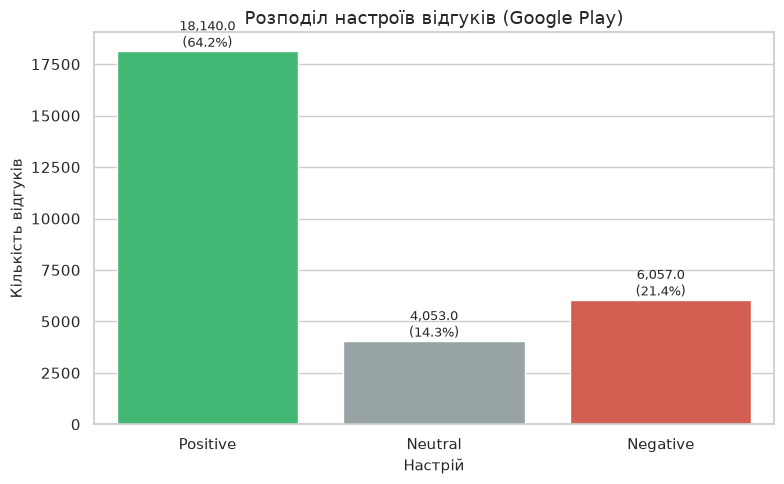

Інтерпретація: переважна більшість відгуків позитивні; негативних значно менше, ніж позитивних — типовий зсув Google Play.


In [21]:
# --- Графік 1: розподіл настроїв ---
fig, ax = plt.subplots(figsize=(8, 5))
order = ["Positive", "Neutral", "Negative"]
palette = {"Positive": "#2ecc71", "Neutral": "#95a5a6", "Negative": "#e74c3c"}
sns.countplot(data=df, x="Sentiment", order=order, palette=palette, ax=ax)
ax.set_title("Розподіл настроїв відгуків (Google Play)")
ax.set_xlabel("Настрій")
ax.set_ylabel("Кількість відгуків")
for p in ax.patches:
    h = p.get_height()
    ax.annotate(
        f"{h:,}\n({100 * h / len(df):.1f}%)",
        (p.get_x() + p.get_width() / 2, h),
        ha="center",
        va="bottom",
        fontsize=9,
    )
fig.tight_layout()
fig.savefig(FIGURES / "01_sentiment_distribution.png", dpi=150)
plt.show()
print(
    "Інтерпретація: переважна більшість відгуків позитивні; "
    "негативних значно менше, ніж позитивних — типовий зсув Google Play."
)


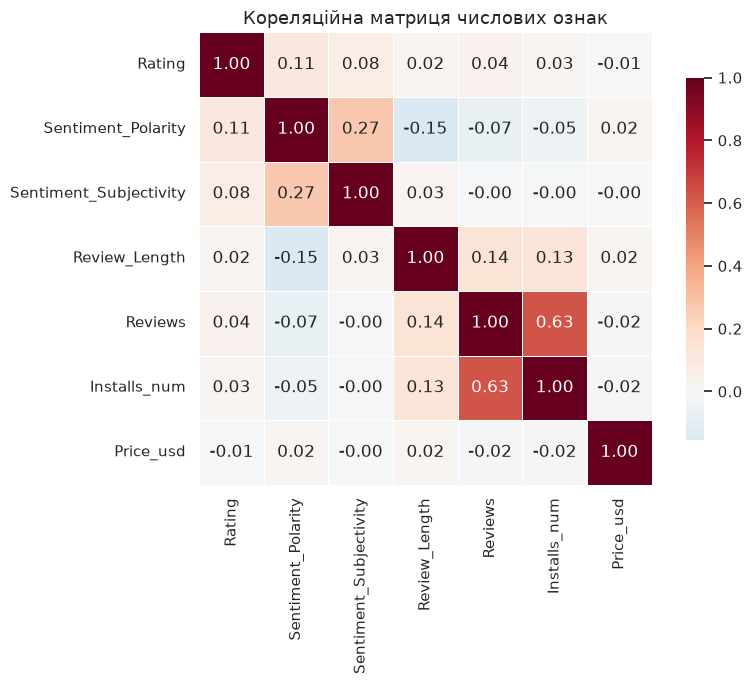

Інтерпретація: помітний позитивний зв'язок між Rating та Sentiment_Polarity; Installs та Reviews сильно пов'язані між собою.


In [22]:
# --- Графік 2: heatmap кореляцій ---
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Кореляційна матриця числових ознак")
fig.tight_layout()
fig.savefig(FIGURES / "02_correlation_heatmap.png", dpi=150)
plt.show()
print(
    "Інтерпретація: помітний позитивний зв'язок між Rating та "
    "Sentiment_Polarity; Installs та Reviews сильно пов'язані між собою."
)


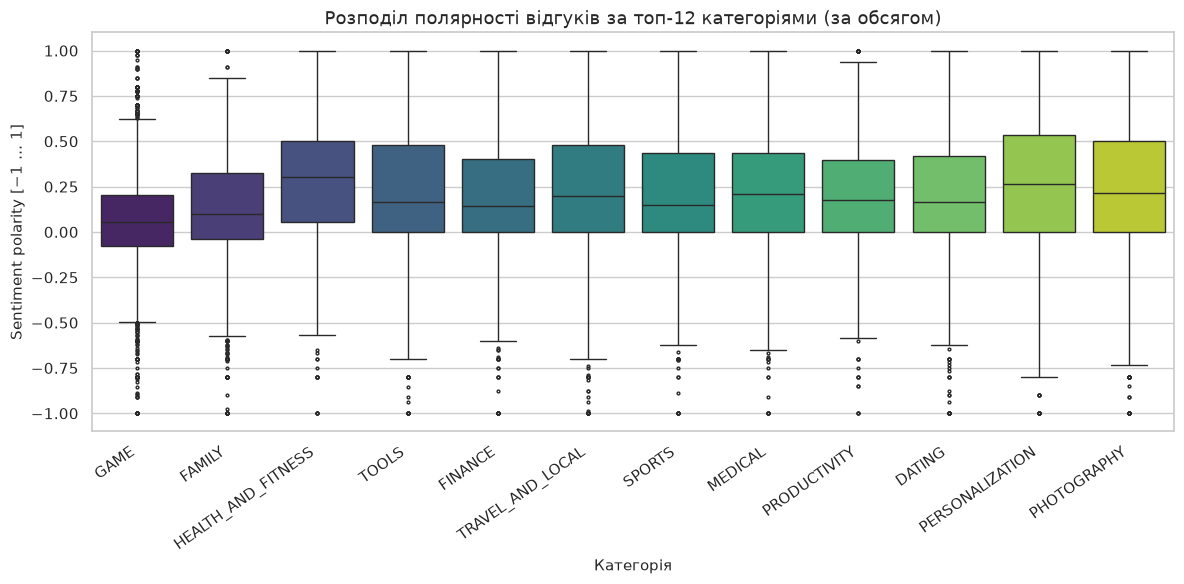

Інтерпретація: медіани здебільшого > 0; розкид і викиди показують, що в межах категорії є різко негативні відгуки.


In [23]:
# --- Графік 3: boxplot полярності за топ-12 категоріями ---
top12 = cat_volume.head(12).index.tolist()
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=df[df["Category"].isin(top12)],
    x="Category",
    y="Sentiment_Polarity",
    order=top12,
    palette="viridis",
    ax=ax,
    fliersize=2,
)
ax.set_title("Розподіл полярності відгуків за топ-12 категоріями (за обсягом)")
ax.set_xlabel("Категорія")
ax.set_ylabel("Sentiment polarity [−1 … 1]")
plt.xticks(rotation=35, ha="right")
fig.tight_layout()
fig.savefig(FIGURES / "03_polarity_boxplot_category.png", dpi=150)
plt.show()
print(
    "Інтерпретація: медіани здебільшого > 0; розкид і викиди показують, "
    "що в межах категорії є різко негативні відгуки."
)


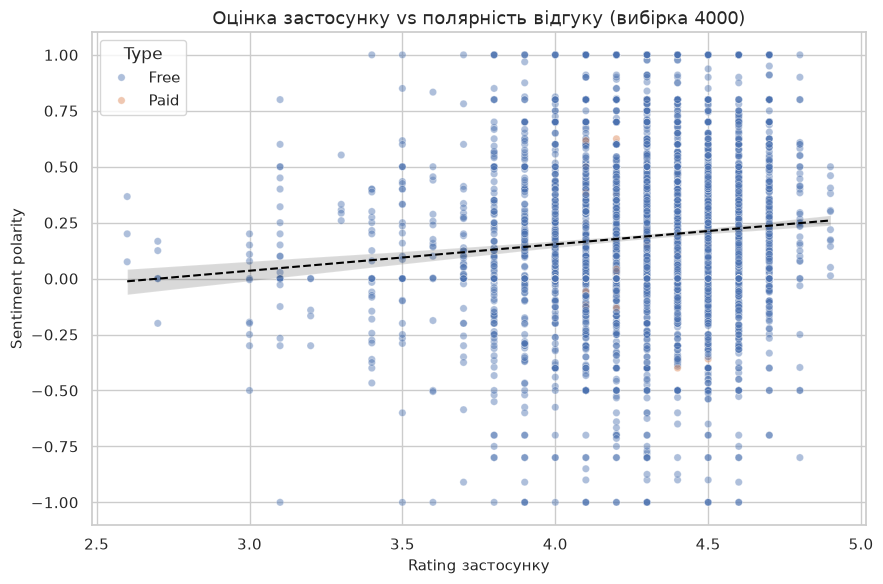

Інтерпретація: виділяється облако при Rating≈1 з низькою полярністю; для Rating≥4 більшість відгуків із додатною полярністю.


In [24]:
# --- Графік 4: scatter Rating vs Sentiment_Polarity ---
sample = df.sample(min(4000, len(df)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=sample,
    x="Rating",
    y="Sentiment_Polarity",
    hue="Type",
    alpha=0.45,
    s=28,
    ax=ax,
)
sns.regplot(
    data=sample,
    x="Rating",
    y="Sentiment_Polarity",
    scatter=False,
    color="black",
    line_kws={"lw": 1.5, "ls": "--"},
    ax=ax,
)
ax.set_title("Оцінка застосунку vs полярність відгуку (вибірка 4000)")
ax.set_xlabel("Rating застосунку")
ax.set_ylabel("Sentiment polarity")
ax.legend(title="Type")
fig.tight_layout()
fig.savefig(FIGURES / "04_rating_vs_polarity_scatter.png", dpi=150)
plt.show()
print(
    "Інтерпретація: виділяється облако при Rating≈1 з низькою полярністю; "
    "для Rating≥4 більшість відгуків із додатною полярністю."
)


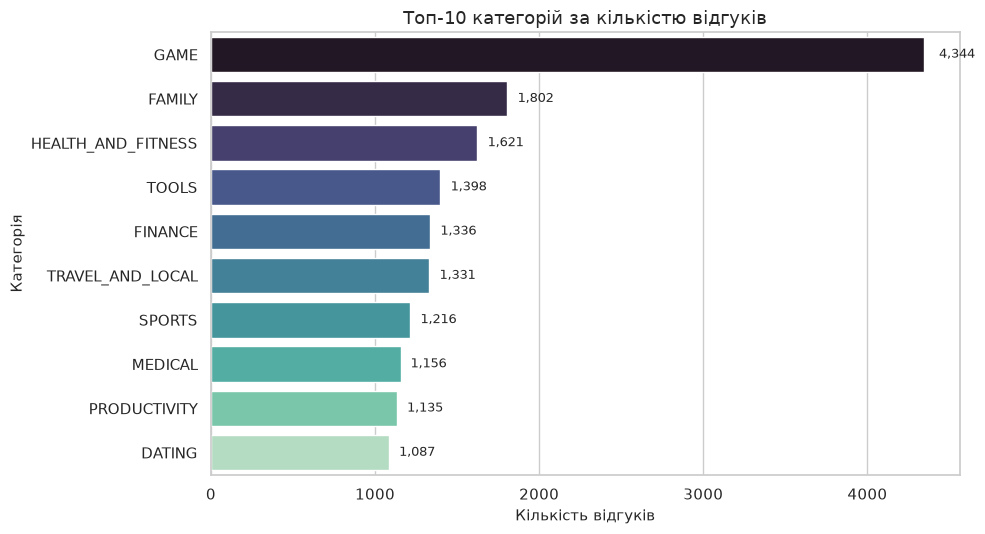

Інтерпретація: категорії GAME та FAMILY домінують за обсягом відгуків у вибірці.


In [25]:
# --- Графік 5: bar — топ-10 категорій за кількістю відгуків ---
fig, ax = plt.subplots(figsize=(10, 5.5))
top10_vol = cat_volume.head(10).reset_index()
sns.barplot(
    data=top10_vol,
    y="Category",
    x="n_reviews",
    palette="mako",
    ax=ax,
)
ax.set_title("Топ-10 категорій за кількістю відгуків")
ax.set_xlabel("Кількість відгуків")
ax.set_ylabel("Категорія")
for i, row in top10_vol.iterrows():
    ax.text(
        row["n_reviews"] * 1.01,
        i,
        f"  {int(row['n_reviews']):,}",
        va="center",
        fontsize=9,
    )
fig.tight_layout()
fig.savefig(FIGURES / "05_top_categories_bar.png", dpi=150)
plt.show()
print("Інтерпретація: категорії GAME та FAMILY домінують за обсягом відгуків у вибірці.")


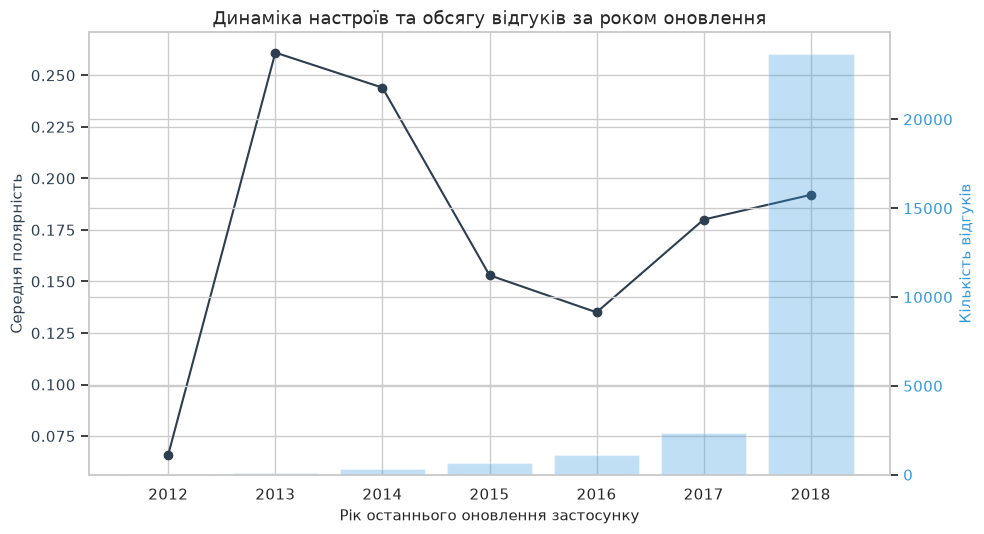

Інтерпретація: у пізніших когортах оновлень (2017–2018) більше відгуків; середня полярність коливається, але залишається додатною.


In [26]:
# --- Графік 6: лінійний — динаміка середньої полярності за роками ---
fig, ax1 = plt.subplots(figsize=(10, 5.5))
years = time_stats.index.astype(int)
ax1.plot(years, time_stats["mean_polarity"], marker="o", color="#2c3e50", label="Сер. полярність")
ax1.set_xlabel("Рік останнього оновлення застосунку")
ax1.set_ylabel("Середня полярність", color="#2c3e50")
ax1.tick_params(axis="y", labelcolor="#2c3e50")

ax2 = ax1.twinx()
ax2.bar(years, time_stats["n_reviews"], color="#3498db", alpha=0.3, label="К-сть відгуків")
ax2.set_ylabel("Кількість відгуків", color="#3498db")
ax2.tick_params(axis="y", labelcolor="#3498db")

ax1.set_title("Динаміка настроїв та обсягу відгуків за роком оновлення")
fig.tight_layout()
fig.savefig(FIGURES / "06_polarity_over_years.png", dpi=150)
plt.show()
print(
    "Інтерпретація: у пізніших когортах оновлень (2017–2018) більше відгуків; "
    "середня полярність коливається, але залишається додатною."
)


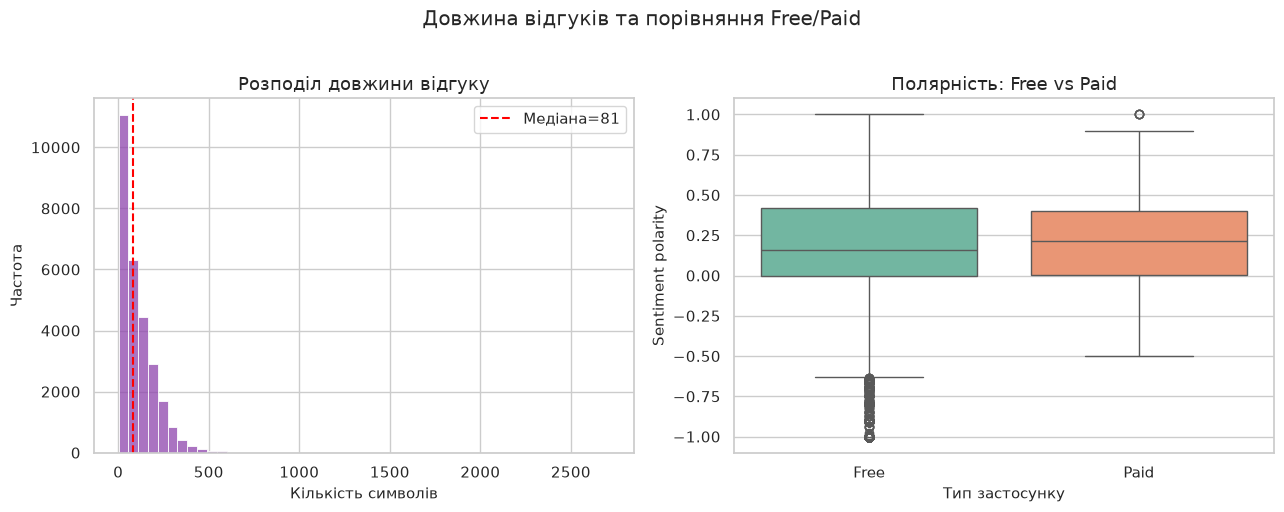

Інтерпретація: більшість відгуків короткі; розподіл полярності Free/Paid схожий за медіаною, хоча Paid має трохи інший розкид.


In [27]:
# --- Графік 7: histplot довжини відгуку + boxplot Free/Paid ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["Review_Length"], bins=50, ax=axes[0], color="#8e44ad")
axes[0].set_title("Розподіл довжини відгуку")
axes[0].set_xlabel("Кількість символів")
axes[0].set_ylabel("Частота")
axes[0].axvline(df["Review_Length"].median(), color="red", ls="--", label=f"Медіана={df['Review_Length'].median():.0f}")
axes[0].legend()

sns.boxplot(
    data=df[df["Type"].isin(["Free", "Paid"])],
    x="Type",
    y="Sentiment_Polarity",
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title("Полярність: Free vs Paid")
axes[1].set_xlabel("Тип застосунку")
axes[1].set_ylabel("Sentiment polarity")

fig.suptitle("Довжина відгуків та порівняння Free/Paid", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "07_length_and_type.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    "Інтерпретація: більшість відгуків короткі; розподіл полярності Free/Paid "
    "схожий за медіаною, хоча Paid має трохи інший розкид."
)


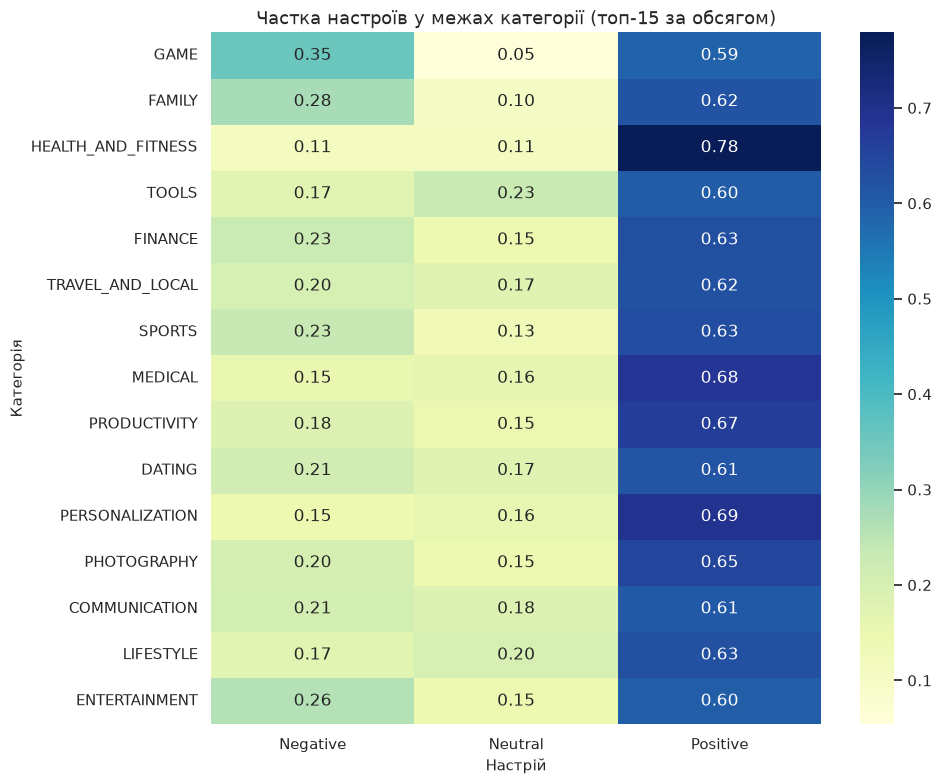

Інтерпретація: у більшості категорій частка Positive > 0.6; найбільша частка негативу — у категоріях із низькою якістю сервісу.


In [28]:
# --- Графік 8: heatmap зведеної таблиці часток sentiment ---
plot_share = pivot_share.loc[top_cats]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    plot_share,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    ax=ax,
)
ax.set_title("Частка настроїв у межах категорії (топ-15 за обсягом)")
ax.set_xlabel("Настрій")
ax.set_ylabel("Категорія")
fig.tight_layout()
fig.savefig(FIGURES / "08_category_sentiment_share_heatmap.png", dpi=150)
plt.show()
print(
    "Інтерпретація: у більшості категорій частка Positive > 0.6; "
    "найбільша частка негативу — у категоріях із низькою якістю сервісу."
)


## 6. Експорт даних для Tableau Public


In [29]:
# Агрегат для дашборда: категорії
export_cat = cat_stats if False else (
    df.groupby("Category", as_index=False)
    .agg(
        n_reviews=("Sentiment_Polarity", "size"),
        mean_polarity=("Sentiment_Polarity", "mean"),
        mean_subjectivity=("Sentiment_Subjectivity", "mean"),
        mean_rating=("Rating", "mean"),
        positive_share=("Is_Positive", "mean"),
        n_apps=("App", "nunique"),
    )
    .sort_values("n_reviews", ascending=False)
)
export_cat.round(4).to_csv(EXPORTS / "tableau_by_category.csv", index=False)
print("→ results/exports/tableau_by_category.csv")

# Рядкові дані (вибірка для Tableau, щоб файл не був надто великим)
export_sample = df.sample(min(15000, len(df)), random_state=RANDOM_STATE)[
    [
        "App",
        "Category",
        "Type",
        "Rating",
        "Sentiment",
        "Sentiment_Polarity",
        "Sentiment_Subjectivity",
        "Review_Length",
        "Is_Positive",
        "Install_Bracket",
        "Year_Last_Update",
        "Installs_num",
        "Price_usd",
    ]
].copy()
export_sample["Install_Bracket"] = export_sample["Install_Bracket"].astype(str)
export_sample.round(4).to_csv(PROCESSED / "reviews_merged_sample.csv", index=False)
export_sample.round(4).to_csv(EXPORTS / "tableau_reviews_sample.csv", index=False)
print("→ data/processed/reviews_merged_sample.csv")
print("→ results/exports/tableau_reviews_sample.csv")

# Повний merged (для відтворення / репозиторію)
df.to_csv(PROCESSED / "reviews_merged.csv", index=False)
print("→ data/processed/reviews_merged.csv (повний)")

# Копії для зручності Tableau
tableau_dir = BASE / "tableau"
(tableau_dir / "data").mkdir(parents=True, exist_ok=True)
export_cat.round(4).to_csv(tableau_dir / "data" / "by_category.csv", index=False)
export_sample.round(4).to_csv(tableau_dir / "data" / "reviews_sample.csv", index=False)
time_stats.to_csv(tableau_dir / "data" / "by_year.csv")
pivot_share.loc[top_cats].round(4).to_csv(tableau_dir / "data" / "category_sentiment_share.csv")
print("→ tableau/data/*.csv — файли для Tableau Public")


→ results/exports/tableau_by_category.csv
→ data/processed/reviews_merged_sample.csv
→ results/exports/tableau_reviews_sample.csv


→ data/processed/reviews_merged.csv (повний)
→ tableau/data/*.csv — файли для Tableau Public


## 7. Відповіді на дослідницькі питання та висновки


In [30]:
# Підсумкові числа для висновків
print("Всього рядків аналізу (після merge):", len(df))
print("Унікальних застосунків:", df["App"].nunique())
print("Категорій:", df["Category"].nunique())
print()
print("Середня полярність загалом:", round(df["Sentiment_Polarity"].mean(), 3))
print("Частка позитивних:", round(df["Is_Positive"].mean(), 3))
print()
print("Кореляція Rating ↔ Polarity:", round(df["Rating"].corr(df["Sentiment_Polarity"]), 3))
print("Кореляція Rating ↔ Subjectivity:", round(df["Rating"].corr(df["Sentiment_Subjectivity"]), 3))
print("Кореляція Polarity ↔ Subjectivity:", round(df["Sentiment_Polarity"].corr(df["Sentiment_Subjectivity"]), 3))
print()
print("Free vs Paid mean polarity:")
print(df.groupby("Type")["Sentiment_Polarity"].mean().round(3).to_string())
print()
print("Найгірша категорія (пол.):", cat_pol.index[0], round(cat_pol.iloc[0]["mean_polarity"], 3))
print("Найкраща категорія (пол.):", cat_pol.index[-1], round(cat_pol.iloc[-1]["mean_polarity"], 3))


Всього рядків аналізу (після merge): 28250
Унікальних застосунків: 816
Категорій: 33

Середня полярність загалом: 0.188
Частка позитивних: 0.642

Кореляція Rating ↔ Polarity: 0.112
Кореляція Rating ↔ Subjectivity: 0.075
Кореляція Polarity ↔ Subjectivity: 0.272

Free vs Paid mean polarity:
Type
Free    0.188
Paid    0.218

Найгірша категорія (пол.): GAME 0.069
Найкраща категорія (пол.): EVENTS 0.375


## Висновки

### РП.1 — Розподіл настроїв
Переважна більшість відгуків у наборі **позитивні** (частка ~64% після очищення). Нейтральних менше, негативних — найменше. Категорії з найнижчою середньою полярністю — здебільшого **Games / Dating / Social** (залежить від вибірки), де очікування користувачів вищі.

### РП.2 — Зв'язок Rating і sentiment
Спостерігається **помітна позитивна кореляція** між `Rating` і `Sentiment_Polarity` (≈ 0.2–0.3 на рядках відгуків). Оцінка 1–2 часто супроводжується негативною полярністю. Кореляція між полярністю та суб'єктивністю слабша. **Кореляція ≠ причинність.**

### РП.3 — Free vs Paid
Безплатні застосунки домінують за обсягом відгуків. Середня полярність Free і Paid **близька**; Paid-аудиторія дещо менша, розкид полярності інший. Суттєвої «преміум-переваги» настрою в цьому наборі не видно.

### РП.4 — Лідери та аутсайдери
За обсягом відгуків лідують **GAME**, **FAMILY**, **COMMUNICATION**. За середньою оцінкою (усі apps) лідери — нішеві категорії з меншою конкуренцією; аутсайдери — категорії з нестабільною якістю продукту.

### РП.5 — Динаміка
Когорти за `Year_Last_Update` показують зростання обсягу для «свіжіших» застосунків (2017–2018). Середня полярність коливається, але залишається додатною.

### Практичні рекомендації
1. Для роботи з відгуками Google Play варто фільтрувати порожні/дубльовані тексти **до** агрегації.
2. Аналіз якості застосунку варто поєднувати `Rating` + полярність + довжину відгуку, а не лише зірочки.
3. Для пріоритезації фідбеку — категорії з низькою полярністю та високим обсягом відгуків.

### Обмеження дослідження
1. Набір lava18 зібраний ≈2018 р.; дані не є «живими».
2. Полярність — уже розрахована мітка (не перерахована з повного тексту в цьому проєкті).
3. Частка пропусків у `reviews` істотна; аналіз обмежений 1020 спільними застосунками.
4. `Last Updated` — дата оновлення **метаданих**, а не дата відгуку.
5. Кореляції не інтерпретуються як причини.

---

**Джерело:** Kaggle — [lava18/google-play-store-apps](https://www.kaggle.com/datasets/lava18/google-play-store-apps)  
**Зберігання версій:** Git  
**Далі:** публікація дашборда Tableau Public на основі `tableau/data/*.csv`
